In [62]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import convolve
import time
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

In [63]:
def create_lstm_sequences(
    received,
    symbols,
    samples_per_symbol=2,
    sequence_length=10
):
    """
    Create sequential waveform inputs for an LSTM.

    Each input is a sequence of consecutive received
    waveform samples.

    The target is the PAM4 symbol aligned with the
    center of the sequence.
    """

    X = []
    y = []

    half = sequence_length // 2

    # Number of symbols we can safely process
    num_symbols = min(
        len(symbols),
        len(received) // samples_per_symbol
    )

    for n in range(half, num_symbols - half):

        # Center sample corresponding to symbol n
        center_sample = n * samples_per_symbol

        # Sequence boundaries
        start = center_sample - half
        end = start + sequence_length

        # Extract waveform sequence
        sequence = received[start:end]

        if len(sequence) != sequence_length:
            continue

        X.append(sequence)

        # Target PAM4 symbol
        y.append(symbols[n])

    return np.array(X), np.array(y)

In [64]:
def apply_channel_fse(
    symbols,
    channel,
    samples_per_symbol,
    snr_db,
    fse_samples_per_symbol=2
):
    """
    Generate received samples for a fractionally-spaced equalizer.
    """

    # Oversample transmitted PAM4 symbols
    tx_waveform = np.repeat(symbols, samples_per_symbol)

    # Apply channel
    rx_noiseless = convolve(
        tx_waveform,
        channel,
        mode="same"
    )

    # Calculate noise power
    signal_power = np.mean(rx_noiseless ** 2)
    snr_linear = 10 ** (snr_db / 10)
    noise_power = signal_power / snr_linear

    # Add AWGN
    noise = np.random.normal(
        0,
        np.sqrt(noise_power),
        len(rx_noiseless)
    )

    rx_signal = rx_noiseless + noise

    # Select evenly spaced samples
    spacing = samples_per_symbol // fse_samples_per_symbol

    sample_indices = np.arange(
        samples_per_symbol // 2,
        len(rx_signal),
        spacing
    )

    rx_samples = rx_signal[sample_indices]

    return rx_samples

In [65]:
def bits_to_pam4(bits):
    bit_pairs = bits.reshape(-1, 2)

    symbols = np.array([
        pam4_mapping[tuple(pair)]
        for pair in bit_pairs
    ])

    return symbols

In [66]:
samples_per_symbol = 10

pam4_mapping = {
    (0, 0): -3,
    (0, 1): -1,
    (1, 1): 1,
    (1, 0): 3
}

pam4_to_bits = {
    -3: (0, 0),
    -1: (0, 1),
     1: (1, 1),
     3: (1, 0)
}

channel = np.array([0.1, 0.2, 0.5, 0.2, 0.1])

channel_test = np.array([
    0.15,
    0.30,
    0.40,
    0.30,
    0.15
])

channel_test = channel_test / np.sum(channel_test)

print("Test channel:", channel_test)

num_bits = 100_000
snr_db = 15

Test channel: [0.11538462 0.23076923 0.30769231 0.23076923 0.11538462]


In [67]:
def pam4_detect(samples):
    detected = np.zeros(len(samples), dtype=int)

    detected[samples < -2] = -3
    detected[(samples >= -2) & (samples < 0)] = -1
    detected[(samples >= 0) & (samples < 2)] = 1
    detected[samples >= 2] = 3

    return detected

In [68]:
# ==========================================
# CREATE LSTM TRAIN / VALIDATION / TEST DATA
# ==========================================

# Training data
train_bits_lstm = np.random.randint(0, 2, 100000)
train_symbols_lstm = bits_to_pam4(train_bits_lstm)

train_received_lstm = apply_channel_fse(
    train_symbols_lstm,
    channel_test,
    samples_per_symbol=2,
    snr_db=14,
    fse_samples_per_symbol=2
)

# Validation data
val_bits_lstm = np.random.randint(0, 2, 20000)
val_symbols_lstm = bits_to_pam4(val_bits_lstm)

val_received_lstm = apply_channel_fse(
    val_symbols_lstm,
    channel_test,
    samples_per_symbol=2,
    snr_db=14,
    fse_samples_per_symbol=2
)

# Test data
test_bits_lstm = np.random.randint(0, 2, 20000)
test_symbols_lstm = bits_to_pam4(test_bits_lstm)

test_received_lstm = apply_channel_fse(
    test_symbols_lstm,
    channel_test,
    samples_per_symbol=2,
    snr_db=14,
    fse_samples_per_symbol=2
)

print("Training symbols:", len(train_symbols_lstm))
print("Validation symbols:", len(val_symbols_lstm))
print("Test symbols:", len(test_symbols_lstm))

print("Training samples:", len(train_received_lstm))
print("Validation samples:", len(val_received_lstm))
print("Test samples:", len(test_received_lstm))

Training symbols: 50000
Validation symbols: 10000
Test symbols: 10000
Training samples: 99999
Validation samples: 19999
Test samples: 19999


In [69]:
SEQUENCE_LENGTH = 10

X_train_lstm, y_train_lstm = create_lstm_sequences(
    train_received_lstm,
    train_symbols_lstm,
    samples_per_symbol=2,
    sequence_length=SEQUENCE_LENGTH
)

X_val_lstm, y_val_lstm = create_lstm_sequences(
    val_received_lstm,
    val_symbols_lstm,
    samples_per_symbol=2,
    sequence_length=SEQUENCE_LENGTH
)

X_test_lstm, y_test_lstm = create_lstm_sequences(
    test_received_lstm,
    test_symbols_lstm,
    samples_per_symbol=2,
    sequence_length=SEQUENCE_LENGTH
)

print("X_train shape:", X_train_lstm.shape)
print("y_train shape:", y_train_lstm.shape)

print("X_val shape:", X_val_lstm.shape)
print("y_val shape:", y_val_lstm.shape)

print("X_test shape:", X_test_lstm.shape)
print("y_test shape:", y_test_lstm.shape)

X_train shape: (49989, 10)
y_train shape: (49989,)
X_val shape: (9989, 10)
y_val shape: (9989,)
X_test shape: (9989, 10)
y_test shape: (9989,)


In [70]:
X_train_lstm = X_train_lstm[:, :, np.newaxis]
X_val_lstm = X_val_lstm[:, :, np.newaxis]
X_test_lstm = X_test_lstm[:, :, np.newaxis]

print("X_train shape:", X_train_lstm.shape)
print("X_val shape:", X_val_lstm.shape)
print("X_test shape:", X_test_lstm.shape)

X_train shape: (49989, 10, 1)
X_val shape: (9989, 10, 1)
X_test shape: (9989, 10, 1)


In [71]:
symbol_to_class = {
    -3: 0,
    -1: 1,
     1: 2,
     3: 3
}

y_train_lstm = np.array([
    symbol_to_class[int(s)]
    for s in y_train_lstm
])

y_val_lstm = np.array([
    symbol_to_class[int(s)]
    for s in y_val_lstm
])

y_test_lstm = np.array([
    symbol_to_class[int(s)]
    for s in y_test_lstm
])

In [72]:
print("Unique training classes:", np.unique(y_train_lstm))
print("First 20 training classes:", y_train_lstm[:20])

Unique training classes: [0 1 2 3]
First 20 training classes: [0 2 2 3 1 0 1 0 2 0 0 1 1 3 3 2 2 0 2 0]


In [73]:
X_train_tensor = torch.tensor(
    X_train_lstm,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_lstm,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_lstm,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_lstm,
    dtype=torch.long
)

y_val_tensor = torch.tensor(
    y_val_lstm,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test_lstm,
    dtype=torch.long
)

In [74]:
X_train_tensor = torch.tensor(
    X_train_lstm,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_lstm,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_lstm,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_lstm,
    dtype=torch.long
)

y_val_tensor = torch.tensor(
    y_val_lstm,
    dtype=torch.long
)

y_test_tensor = torch.tensor(
    y_test_lstm,
    dtype=torch.long
)

In [75]:
print("X_train tensor:", X_train_tensor.shape)
print("y_train tensor:", y_train_tensor.shape)

print("X_train dtype:", X_train_tensor.dtype)
print("y_train dtype:", y_train_tensor.dtype)

X_train tensor: torch.Size([49989, 10, 1])
y_train tensor: torch.Size([49989])
X_train dtype: torch.float32
y_train dtype: torch.int64


In [76]:
class LSTMEqualizer(nn.Module):

    def __init__(
        self,
        input_size=1,
        hidden_size=32,
        num_layers=1,
        num_classes=4
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size,
            num_classes
        )

    def forward(self, x):

        # LSTM processes the waveform sequence
        lstm_output, (hidden_state, cell_state) = self.lstm(x)

        # Take the final timestep's output
        final_output = lstm_output[:, -1, :]

        # Convert to 4 PAM4 class scores
        output = self.fc(final_output)

        return output

In [77]:
lstm_model = LSTMEqualizer(
    input_size=1,
    hidden_size=32,
    num_layers=1,
    num_classes=4
)

print(lstm_model)

LSTMEqualizer(
  (lstm): LSTM(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=4, bias=True)
)


In [78]:
lstm_parameters = sum(
    p.numel()
    for p in lstm_model.parameters()
    if p.requires_grad
)

print("LSTM trainable parameters:", lstm_parameters)

LSTM trainable parameters: 4612


In [79]:
BATCH_SIZE = 256

train_dataset_lstm = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

val_dataset_lstm = TensorDataset(
    X_val_tensor,
    y_val_tensor
)

test_dataset_lstm = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

train_loader_lstm = DataLoader(
    train_dataset_lstm,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_lstm = DataLoader(
    val_dataset_lstm,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader_lstm = DataLoader(
    test_dataset_lstm,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [80]:
device = torch.device(
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Using device:", device)

Using device: mps


In [81]:
lstm_model = lstm_model.to(device)

In [82]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [83]:
X_batch, y_batch = next(iter(train_loader_lstm))

print("Batch X shape:", X_batch.shape)
print("Batch y shape:", y_batch.shape)

Batch X shape: torch.Size([256, 10, 1])
Batch y shape: torch.Size([256])


In [84]:
X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

with torch.no_grad():
    test_output = lstm_model(X_batch)

print("Model output shape:", test_output.shape)

Model output shape: torch.Size([256, 4])


In [85]:
import time

NUM_EPOCHS = 10

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

start_time = time.time()

for epoch in range(NUM_EPOCHS):

    # ==========================
    # TRAINING
    # ==========================

    lstm_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in train_loader_lstm:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Clear old gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = lstm_model(X_batch)

        # Calculate loss
        loss = criterion(outputs, y_batch)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Track statistics
        running_loss += loss.item() * X_batch.size(0)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            (predictions == y_batch)
            .sum()
            .item()
        )

        total += y_batch.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total

    # ==========================
    # VALIDATION
    # ==========================

    lstm_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader_lstm:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = lstm_model(X_batch)

            loss = criterion(
                outputs,
                y_batch
            )

            val_running_loss += (
                loss.item()
                * X_batch.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            val_correct += (
                (predictions == y_batch)
                .sum()
                .item()
            )

            val_total += y_batch.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = val_correct / val_total

    # Save history
    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch {epoch + 1:2d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

training_time = time.time() - start_time

print()
print(f"LSTM training time: {training_time:.6f} seconds")

Epoch  1/10 | Train Loss: 1.129943 | Train Acc: 0.4647 | Val Loss: 0.884839 | Val Acc: 0.5905
Epoch  2/10 | Train Loss: 0.677273 | Train Acc: 0.7021 | Val Loss: 0.552235 | Val Acc: 0.7696
Epoch  3/10 | Train Loss: 0.499623 | Train Acc: 0.7966 | Val Loss: 0.469837 | Val Acc: 0.8056
Epoch  4/10 | Train Loss: 0.450182 | Train Acc: 0.8151 | Val Loss: 0.435502 | Val Acc: 0.8182
Epoch  5/10 | Train Loss: 0.420369 | Train Acc: 0.8278 | Val Loss: 0.412827 | Val Acc: 0.8311
Epoch  6/10 | Train Loss: 0.400496 | Train Acc: 0.8342 | Val Loss: 0.391783 | Val Acc: 0.8362
Epoch  7/10 | Train Loss: 0.391947 | Train Acc: 0.8370 | Val Loss: 0.401883 | Val Acc: 0.8311
Epoch  8/10 | Train Loss: 0.377134 | Train Acc: 0.8430 | Val Loss: 0.432383 | Val Acc: 0.8151
Epoch  9/10 | Train Loss: 0.370642 | Train Acc: 0.8460 | Val Loss: 0.361193 | Val Acc: 0.8522
Epoch 10/10 | Train Loss: 0.360100 | Train Acc: 0.8489 | Val Loss: 0.356573 | Val Acc: 0.8512

LSTM training time: 11.789601 seconds


In [86]:
lstm_model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():

    for X_batch, y_batch in test_loader_lstm:

        X_batch = X_batch.to(device)

        outputs = lstm_model(X_batch)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_targets.extend(
            y_batch.numpy()
        )

all_predictions = np.array(all_predictions)
all_targets = np.array(all_targets)

print("First 20 LSTM predictions:")
print(all_predictions[:20])

print()

print("First 20 actual classes:")
print(all_targets[:20])

First 20 LSTM predictions:
[2 2 1 2 1 3 3 0 2 2 2 1 1 2 3 3 3 1 3 0]

First 20 actual classes:
[1 3 0 3 1 3 3 0 2 2 2 1 1 2 3 3 3 1 3 0]


In [87]:
# PAM4 symbol → 2-bit mapping
bit_map = {
    -3: [0, 0],
    -1: [0, 1],
     1: [1, 0],
     3: [1, 1]
}

lstm_predicted_bits = np.array([
    bit
    for symbol in lstm_predicted_symbols
    for bit in bit_map[int(symbol)]
])

lstm_actual_bits = np.array([
    bit
    for symbol in lstm_actual_symbols
    for bit in bit_map[int(symbol)]
])

bit_errors = np.sum(
    lstm_predicted_bits != lstm_actual_bits
)

total_bits = len(lstm_actual_bits)

lstm_ber = bit_errors / total_bits

print("========== LSTM RESULT ==========")
print("SNR: 14 dB")
print("Bit errors:", bit_errors)
print("Total bits:", total_bits)
print(f"BER: {lstm_ber:.6f}")

========== LSTM RESULT ==========
SNR: 14 dB
Bit errors: 1944
Total bits: 19978
BER: 0.097307


In [88]:
print("Predicted class distribution:")
print(np.bincount(all_predictions, minlength=4))

print()

print("Actual class distribution:")
print(np.bincount(all_targets, minlength=4))

Predicted class distribution:
[2609 2425 2549 2406]

Actual class distribution:
[2492 2507 2480 2510]


In [89]:
print("First 50 predicted symbols:")
print(lstm_predicted_symbols[:50])

print()

print("First 50 actual symbols:")
print(lstm_actual_symbols[:50])

First 50 predicted symbols:
[ 1  1  3  1  3  3 -1 -3  1  1  3  1  3 -1 -3 -1 -3  1  1  1  3 -1  3  1
 -3  1 -1 -3 -1  1 -1 -3  3  3 -3  3 -1  3 -1 -1  1  1  1  3 -3  1  1 -1
  3  1]

First 50 actual symbols:
[ 3  1  3  1  3  3 -1 -3  1  1  3  1  3 -1 -3 -1 -3  1  3 -1  3 -1  3 -1
 -3  1  1 -3 -1 -1  1 -3  3  3 -3  3 -3  3 -3 -1  1  1  1  3 -3  1  1 -1
  3  1]


In [90]:
print("First LSTM sequence:")
print(X_train_lstm[0, :, 0])

print()

print("First target class:")
print(y_train_lstm[0])

print(
    "First target PAM4 symbol:",
    class_to_symbol[int(y_train_lstm[0])]
)

First LSTM sequence:
[ 1.72955558  0.76205842 -1.09169131 -2.20833366 -2.43009892 -1.72744387
 -0.07133349  0.71839125  0.67438257  2.12752869]

First target class:
0
First target PAM4 symbol: -3


In [91]:
print("Corresponding transmitted symbols around first target:")

# The first sequence starts at symbol index 5
print(train_symbols_lstm[:12])

Corresponding transmitted symbols around first target:
[ 1  1  1  3 -3 -3  1  1  3 -1 -3 -1]


In [92]:
snr_values = np.arange(0, 21, 2)

lstm_ber_results = []

lstm_model.eval()

for snr_db in snr_values:

    # Generate fresh test data
    bits = np.random.randint(0, 2, 20000)
    symbols = bits_to_pam4(bits)

    received = apply_channel_fse(
        symbols,
        channel_test,
        samples_per_symbol=2,
        snr_db=snr_db,
        fse_samples_per_symbol=2
    )

    # Create LSTM sequences
    X_snr, y_snr = create_lstm_sequences(
        received,
        symbols,
        samples_per_symbol=2,
        sequence_length=SEQUENCE_LENGTH
    )

    # Add feature dimension
    X_snr = X_snr[:, :, np.newaxis]

    # Convert symbols to classes
    y_snr_classes = np.array([
        symbol_to_class[int(s)]
        for s in y_snr
    ])

    # Convert to tensors
    X_snr_tensor = torch.tensor(
        X_snr,
        dtype=torch.float32
    )

    y_snr_tensor = torch.tensor(
        y_snr_classes,
        dtype=torch.long
    )

    # DataLoader
    snr_dataset = TensorDataset(
        X_snr_tensor,
        y_snr_tensor
    )

    snr_loader = DataLoader(
        snr_dataset,
        batch_size=256,
        shuffle=False
    )

    predictions = []
    actual = []

    with torch.no_grad():

        for X_batch, y_batch in snr_loader:

            X_batch = X_batch.to(device)

            outputs = lstm_model(X_batch)

            pred = torch.argmax(
                outputs,
                dim=1
            )

            predictions.extend(
                pred.cpu().numpy()
            )

            actual.extend(
                y_batch.numpy()
            )

    predictions = np.array(predictions)
    actual = np.array(actual)

    # Convert classes back to PAM4 symbols
    predicted_symbols = np.array([
        class_to_symbol[int(c)]
        for c in predictions
    ])

    actual_symbols = np.array([
        class_to_symbol[int(c)]
        for c in actual
    ])

    # Convert PAM4 symbols to bits
    predicted_bits = np.array([
        bit
        for symbol in predicted_symbols
        for bit in bit_map[int(symbol)]
    ])

    actual_bits = np.array([
        bit
        for symbol in actual_symbols
        for bit in bit_map[int(symbol)]
    ])

    # BER
    bit_errors = np.sum(
        predicted_bits != actual_bits
    )

    total_bits = len(actual_bits)

    ber = bit_errors / total_bits

    lstm_ber_results.append(ber)

    print(
        f"SNR = {snr_db:2d} dB | "
        f"LSTM BER = {ber:.6f}"
    )

SNR =  0 dB | LSTM BER = 0.327210
SNR =  2 dB | LSTM BER = 0.302683
SNR =  4 dB | LSTM BER = 0.278256
SNR =  6 dB | LSTM BER = 0.237211
SNR =  8 dB | LSTM BER = 0.206327
SNR = 10 dB | LSTM BER = 0.165332
SNR = 12 dB | LSTM BER = 0.125438
SNR = 14 dB | LSTM BER = 0.092502
SNR = 16 dB | LSTM BER = 0.071328
SNR = 18 dB | LSTM BER = 0.055611
SNR = 20 dB | LSTM BER = 0.050856


In [93]:
SEQUENCE_LENGTH_V2 = 20

X_train_lstm_v2, y_train_lstm_v2 = create_lstm_sequences(
    train_received_lstm,
    train_symbols_lstm,
    samples_per_symbol=2,
    sequence_length=SEQUENCE_LENGTH_V2
)

X_val_lstm_v2, y_val_lstm_v2 = create_lstm_sequences(
    val_received_lstm,
    val_symbols_lstm,
    samples_per_symbol=2,
    sequence_length=SEQUENCE_LENGTH_V2
)

X_test_lstm_v2, y_test_lstm_v2 = create_lstm_sequences(
    test_received_lstm,
    test_symbols_lstm,
    samples_per_symbol=2,
    sequence_length=SEQUENCE_LENGTH_V2
)

print("X_train:", X_train_lstm_v2.shape)
print("y_train:", y_train_lstm_v2.shape)

print("X_val:", X_val_lstm_v2.shape)
print("y_val:", y_val_lstm_v2.shape)

print("X_test:", X_test_lstm_v2.shape)
print("y_test:", y_test_lstm_v2.shape)

X_train: (49979, 20)
y_train: (49979,)
X_val: (9979, 20)
y_val: (9979,)
X_test: (9979, 20)
y_test: (9979,)


In [94]:
X_train_lstm_v2 = X_train_lstm_v2[:, :, np.newaxis]
X_val_lstm_v2 = X_val_lstm_v2[:, :, np.newaxis]
X_test_lstm_v2 = X_test_lstm_v2[:, :, np.newaxis]

print("X_train:", X_train_lstm_v2.shape)

X_train: (49979, 20, 1)


In [95]:
y_train_lstm_v2 = np.array([
    symbol_to_class[int(s)]
    for s in y_train_lstm_v2
])

y_val_lstm_v2 = np.array([
    symbol_to_class[int(s)]
    for s in y_val_lstm_v2
])

y_test_lstm_v2 = np.array([
    symbol_to_class[int(s)]
    for s in y_test_lstm_v2
])

In [96]:
print("Unique classes:", np.unique(y_train_lstm_v2))

Unique classes: [0 1 2 3]


In [97]:
X_train_tensor_v2 = torch.tensor(
    X_train_lstm_v2,
    dtype=torch.float32
)

X_val_tensor_v2 = torch.tensor(
    X_val_lstm_v2,
    dtype=torch.float32
)

X_test_tensor_v2 = torch.tensor(
    X_test_lstm_v2,
    dtype=torch.float32
)

y_train_tensor_v2 = torch.tensor(
    y_train_lstm_v2,
    dtype=torch.long
)

y_val_tensor_v2 = torch.tensor(
    y_val_lstm_v2,
    dtype=torch.long
)

y_test_tensor_v2 = torch.tensor(
    y_test_lstm_v2,
    dtype=torch.long
)

In [98]:
BATCH_SIZE = 256

train_dataset_lstm_v2 = TensorDataset(
    X_train_tensor_v2,
    y_train_tensor_v2
)

val_dataset_lstm_v2 = TensorDataset(
    X_val_tensor_v2,
    y_val_tensor_v2
)

test_dataset_lstm_v2 = TensorDataset(
    X_test_tensor_v2,
    y_test_tensor_v2
)

train_loader_lstm_v2 = DataLoader(
    train_dataset_lstm_v2,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_lstm_v2 = DataLoader(
    val_dataset_lstm_v2,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader_lstm_v2 = DataLoader(
    test_dataset_lstm_v2,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [99]:
lstm_model_v2 = LSTMEqualizer(
    input_size=1,
    hidden_size=32,
    num_layers=1,
    num_classes=4
)

print(lstm_model_v2)

LSTMEqualizer(
  (lstm): LSTM(1, 32, batch_first=True)
  (fc): Linear(in_features=32, out_features=4, bias=True)
)


In [100]:
lstm_parameters_v2 = sum(
    p.numel()
    for p in lstm_model_v2.parameters()
    if p.requires_grad
)

print("LSTM v2 trainable parameters:", lstm_parameters_v2)

LSTM v2 trainable parameters: 4612


In [101]:
lstm_model_v2 = lstm_model_v2.to(device)

In [102]:
criterion_v2 = nn.CrossEntropyLoss()

optimizer_v2 = torch.optim.Adam(
    lstm_model_v2.parameters(),
    lr=0.001
)

In [103]:
X_batch, y_batch = next(
    iter(train_loader_lstm_v2)
)

X_batch = X_batch.to(device)
y_batch = y_batch.to(device)

with torch.no_grad():
    output = lstm_model_v2(X_batch)

print("Input shape:", X_batch.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([256, 20, 1])
Output shape: torch.Size([256, 4])


In [104]:
NUM_EPOCHS_V2 = 10

train_losses_v2 = []
train_accuracies_v2 = []

val_losses_v2 = []
val_accuracies_v2 = []

start_time = time.time()

for epoch in range(NUM_EPOCHS_V2):

    # ==========================
    # TRAINING
    # ==========================

    lstm_model_v2.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in train_loader_lstm_v2:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer_v2.zero_grad()

        outputs = lstm_model_v2(X_batch)

        loss = criterion_v2(
            outputs,
            y_batch
        )

        loss.backward()

        optimizer_v2.step()

        running_loss += (
            loss.item()
            * X_batch.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            (predictions == y_batch)
            .sum()
            .item()
        )

        total += y_batch.size(0)

    train_loss = running_loss / total
    train_accuracy = correct / total

    # ==========================
    # VALIDATION
    # ==========================

    lstm_model_v2.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for X_batch, y_batch in val_loader_lstm_v2:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            outputs = lstm_model_v2(X_batch)

            loss = criterion_v2(
                outputs,
                y_batch
            )

            val_running_loss += (
                loss.item()
                * X_batch.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            val_correct += (
                (predictions == y_batch)
                .sum()
                .item()
            )

            val_total += y_batch.size(0)

    val_loss = val_running_loss / val_total
    val_accuracy = val_correct / val_total

    train_losses_v2.append(train_loss)
    train_accuracies_v2.append(train_accuracy)

    val_losses_v2.append(val_loss)
    val_accuracies_v2.append(val_accuracy)

    print(
        f"Epoch {epoch + 1:2d}/{NUM_EPOCHS_V2} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.6f} | "
        f"Val Acc: {val_accuracy:.4f}"
    )

training_time_v2 = time.time() - start_time

print()
print(
    f"LSTM v2 training time: "
    f"{training_time_v2:.6f} seconds"
)

Epoch  1/10 | Train Loss: 1.301862 | Train Acc: 0.3540 | Val Loss: 1.209230 | Val Acc: 0.4228
Epoch  2/10 | Train Loss: 0.947023 | Train Acc: 0.5652 | Val Loss: 0.651807 | Val Acc: 0.7229
Epoch  3/10 | Train Loss: 0.548098 | Train Acc: 0.7713 | Val Loss: 0.472362 | Val Acc: 0.8073
Epoch  4/10 | Train Loss: 0.461952 | Train Acc: 0.8075 | Val Loss: 0.433284 | Val Acc: 0.8178
Epoch  5/10 | Train Loss: 0.427748 | Train Acc: 0.8235 | Val Loss: 0.411936 | Val Acc: 0.8342
Epoch  6/10 | Train Loss: 0.407329 | Train Acc: 0.8310 | Val Loss: 0.420723 | Val Acc: 0.8190
Epoch  7/10 | Train Loss: 0.408811 | Train Acc: 0.8299 | Val Loss: 0.399963 | Val Acc: 0.8270
Epoch  8/10 | Train Loss: 0.383195 | Train Acc: 0.8433 | Val Loss: 0.367350 | Val Acc: 0.8507
Epoch  9/10 | Train Loss: 0.375710 | Train Acc: 0.8454 | Val Loss: 0.377651 | Val Acc: 0.8438
Epoch 10/10 | Train Loss: 0.370652 | Train Acc: 0.8467 | Val Loss: 0.392912 | Val Acc: 0.8408

LSTM v2 training time: 14.227328 seconds


In [105]:
lstm_model_v2.eval()

all_predictions_v2 = []
all_targets_v2 = []

with torch.no_grad():

    for X_batch, y_batch in test_loader_lstm_v2:

        X_batch = X_batch.to(device)

        outputs = lstm_model_v2(X_batch)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions_v2.extend(
            predictions.cpu().numpy()
        )

        all_targets_v2.extend(
            y_batch.numpy()
        )

all_predictions_v2 = np.array(all_predictions_v2)
all_targets_v2 = np.array(all_targets_v2)

# Convert classes → PAM4 symbols
lstm_predicted_symbols_v2 = np.array([
    class_to_symbol[int(c)]
    for c in all_predictions_v2
])

lstm_actual_symbols_v2 = np.array([
    class_to_symbol[int(c)]
    for c in all_targets_v2
])

# Convert PAM4 symbols → bits
lstm_predicted_bits_v2 = np.array([
    bit
    for symbol in lstm_predicted_symbols_v2
    for bit in bit_map[int(symbol)]
])

lstm_actual_bits_v2 = np.array([
    bit
    for symbol in lstm_actual_symbols_v2
    for bit in bit_map[int(symbol)]
])

bit_errors_v2 = np.sum(
    lstm_predicted_bits_v2 != lstm_actual_bits_v2
)

total_bits_v2 = len(lstm_actual_bits_v2)

lstm_ber_v2 = bit_errors_v2 / total_bits_v2

print("========== LSTM v2 RESULT ==========")
print("SNR: 14 dB")
print("Bit errors:", bit_errors_v2)
print("Total bits:", total_bits_v2)
print(f"BER: {lstm_ber_v2:.6f}")

========== LSTM v2 RESULT ==========
SNR: 14 dB
Bit errors: 2094
Total bits: 19958
BER: 0.104920


In [106]:
lstm_model.eval()

# Use one full test batch
X_latency, _ = next(iter(test_loader_lstm))

X_latency = X_latency.to(device)

# Warm-up
with torch.no_grad():
    for _ in range(10):
        _ = lstm_model(X_latency)

# Synchronize MPS before timing
if device.type == "mps":
    torch.mps.synchronize()

start_time = time.time()

with torch.no_grad():
    _ = lstm_model(X_latency)

if device.type == "mps":
    torch.mps.synchronize()

lstm_inference_time = time.time() - start_time

print(
    f"LSTM inference time: "
    f"{lstm_inference_time:.6f} seconds"
)

LSTM inference time: 0.002447 seconds


In [107]:
lstm_time_per_sample = lstm_inference_time / 256

print(
    f"LSTM inference time per sequence: "
    f"{lstm_time_per_sample:.9f} seconds"
)

LSTM inference time per sequence: 0.000009557 seconds


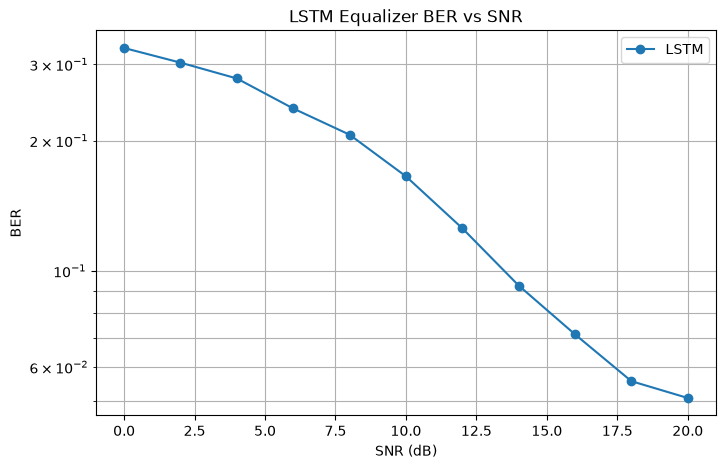

In [108]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.semilogy(
    snr_values,
    lstm_ber_results,
    marker="o",
    label="LSTM"
)

plt.xlabel("SNR (dB)")
plt.ylabel("BER")
plt.title("LSTM Equalizer BER vs SNR")

plt.grid(True, which="both")
plt.legend()

plt.show()

In [109]:
# ============================================
# STANDARDIZED INFERENCE BENCHMARK
# ============================================

BENCHMARK_SYMBOLS = 10_000
NUM_RUNS = 20

print("Benchmark symbols:", BENCHMARK_SYMBOLS)
print("Timing runs:", NUM_RUNS)

Benchmark symbols: 10000
Timing runs: 20


In [110]:
# ============================================
# CREATE STANDARDIZED BENCHMARK INPUT
# ============================================

benchmark_bits = np.random.randint(
    0, 2, BENCHMARK_SYMBOLS * 2
)

benchmark_symbols = bits_to_pam4(benchmark_bits)

benchmark_received = apply_channel_fse(
    benchmark_symbols,
    channel_test,
    samples_per_symbol=2,
    snr_db=14
)

print("Benchmark symbols:", len(benchmark_symbols))
print("Benchmark received samples:", len(benchmark_received))

Benchmark symbols: 10000
Benchmark received samples: 19999


In [113]:
# ============================================
# LSTM INFERENCE BENCHMARK
# ============================================

lstm_model_v2.eval()

X_lstm_benchmark = X_test_tensor_v2[:BENCHMARK_SYMBOLS].to(device)

print("LSTM benchmark shape:", X_lstm_benchmark.shape)

# Warm-up
with torch.no_grad():
    _ = lstm_model_v2(X_lstm_benchmark)

times = []

for _ in range(NUM_RUNS):
    start = time.perf_counter()

    with torch.no_grad():
        _ = lstm_model_v2(X_lstm_benchmark)

    end = time.perf_counter()
    times.append(end - start)

lstm_benchmark_time = np.mean(times)

print(
    f"LSTM inference time for "
    f"{BENCHMARK_SYMBOLS:,} symbols: "
    f"{lstm_benchmark_time:.6f} s"
)

print(
    f"LSTM time per symbol: "
    f"{lstm_benchmark_time / BENCHMARK_SYMBOLS:.9f} s"
)

LSTM benchmark shape: torch.Size([9979, 20, 1])
LSTM inference time for 10,000 symbols: 0.001571 s
LSTM time per symbol: 0.000000157 s


In [112]:
print("LSTM-related variables:")
print([x for x in globals() if "lstm" in x.lower()])

print("\nTensor variables:")
print([
    x for x in globals()
    if "tensor" in x.lower()
])

LSTM-related variables:
['create_lstm_sequences', 'train_bits_lstm', 'train_symbols_lstm', 'train_received_lstm', 'val_bits_lstm', 'val_symbols_lstm', 'val_received_lstm', 'test_bits_lstm', 'test_symbols_lstm', 'test_received_lstm', 'X_train_lstm', 'y_train_lstm', 'X_val_lstm', 'y_val_lstm', 'X_test_lstm', 'y_test_lstm', 'LSTMEqualizer', 'lstm_model', 'lstm_parameters', 'train_dataset_lstm', 'val_dataset_lstm', 'test_dataset_lstm', 'train_loader_lstm', 'val_loader_lstm', 'test_loader_lstm', 'lstm_predicted_symbols', 'lstm_actual_symbols', 'lstm_predicted_bits', 'lstm_actual_bits', 'lstm_ber', 'lstm_ber_results', 'X_train_lstm_v2', 'y_train_lstm_v2', 'X_val_lstm_v2', 'y_val_lstm_v2', 'X_test_lstm_v2', 'y_test_lstm_v2', 'train_dataset_lstm_v2', 'val_dataset_lstm_v2', 'test_dataset_lstm_v2', 'train_loader_lstm_v2', 'val_loader_lstm_v2', 'test_loader_lstm_v2', 'lstm_model_v2', 'lstm_parameters_v2', 'lstm_predicted_symbols_v2', 'lstm_actual_symbols_v2', 'lstm_predicted_bits_v2', 'lstm_actua